# 06 — Оценка параметров модели по дневным данным S&P 500

Практическая часть, шаг 1. Для каждого месяца из `D=21` торговых дней по окну из `W`
предыдущих дней оцениваются снос `a = D·mean(r)`, показатель Херста `H` (R/S-анализ
приростов лог-цены без тренда), масштаб `σ = СКО(r)·D^H` и нормированный снос
`μ = a/σ`. Строятся доверительные интервалы оценок (параметрический бутстреп), и
оценки накладываются на практические границы `μ₁(H)`, `μ₂(H)` выбранного прогона.

Ноутбук ничего не обучает и стратегий не применяет. Границы читаются из прогона
`RUN_ID` при допуске `EPSILON` (файл создаёт `04-grid-analysis.ipynb`).

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
C1, C2, C3, C4, C5 = "#2a78d6", "#eb6834", "#1baf7a", "#8e63d2", "#b8860b"
INK, MUTED = "#0b0b0b", "#8a8a86"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.grid": True, "grid.color": "#e8e8e4", "grid.linewidth": 0.8,
    "lines.linewidth": 1.6, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
    "legend.frameon": False,
})

from osfbm.data import block_frame, fetch_prices, month_blocks
from osfbm.estimation import (bootstrap_estimates, estimate, percentile_ci,
                              rolling_estimates)
from osfbm.policy_bank import CASH, HOLD, POLICY, Boundaries


## Параметры

`RUN_ID` и `EPSILON` задают прогон и допуск, по которым берутся границы. `WINDOW` —
базовое окно оценки в торговых днях, `WINDOWS` — окна для сравнения. `N_BOOT` — число
бутстреп-реплик на дату; `BOOT_EVERY=1` считает интервалы для каждого месяца
(несколько минут), большее значение прореживает даты.

In [3]:
RUN_ID = "daily21_21_train20k_test20k_v1"
EPSILON = 0.06
CONFIDENCE = 0.95
TICKER = "^GSPC"
REFRESH_DATA = False          # True: заново скачать котировки с Yahoo Finance
D = 21
WINDOW = 504
WINDOWS = (126, 252, 504, 1008)
HURST_METHOD = "rs"           # "rs" (R/S, основной) или "dfa" (контроль)
N_BOOT = 200
BOOT_EVERY = 1
OUT = ROOT / "result_optimal_stopping" / "empirical" / RUN_ID / f"estimation_eps{EPSILON:g}"
OUT.mkdir(parents=True, exist_ok=True)

## Границы выбранного прогона

In [4]:
RUN_DIR = ROOT / "result_optimal_stopping" / "runs" / RUN_ID
BOUNDARIES_CSV = RUN_DIR / "analysis" / f"epsilon_{EPSILON:g}" / f"confidence_{CONFIDENCE:g}" / "boundaries.csv"
if not BOUNDARIES_CSV.exists():
    raise SystemExit(f"Нет файла границ {BOUNDARIES_CSV}: выполните 04-grid-analysis.ipynb "
                     f"с RUN_ID={RUN_ID!r} и EPSILON={EPSILON:g}")
boundaries = Boundaries.from_csv(BOUNDARIES_CSV, EPSILON, RUN_ID)
print("Границы:", BOUNDARIES_CSV)
display(boundaries.frame().T.style.format(precision=2, na_rep="—"))

Границы: /Users/armkilikia/optimal-stopping-fbm/result_optimal_stopping/runs/daily21_21_train20k_test20k_v1/analysis/epsilon_0.06/confidence_0.95/boundaries.csv


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46
H,0.06,0.08,0.10,0.12,0.14,0.16,0.18,0.20,0.22,0.24,0.26,0.28,0.30,0.32,0.34,0.36,0.38,0.40,0.42,0.44,0.46,0.48,0.50,0.52,0.54,0.56,0.58,0.60,0.62,0.64,0.66,0.68,0.70,0.72,0.74,0.76,0.78,0.80,0.82,0.84,0.86,0.88,0.90,0.92,0.94,0.96,0.98
mu1,-3.11,-2.78,-2.51,-2.19,-1.94,-1.83,-1.58,-1.42,-1.20,-1.04,-0.96,-0.79,-0.65,-0.52,-0.44,-0.32,-0.23,-0.14,-0.07,-0.01,0.02,0.05,0.06,0.05,0.02,-0.02,-0.03,-0.09,-0.13,-0.18,-0.24,-0.26,-0.31,-0.35,-0.41,-0.46,-0.49,-0.50,-0.56,-0.59,-0.61,-0.67,-0.70,-0.74,-0.76,-0.79,-0.83
mu2,—,7.70,7.33,5.54,4.47,3.85,3.36,3.27,2.52,1.82,1.77,1.23,1.29,0.79,0.71,0.52,0.29,0.16,0.09,0.02,-0.02,-0.06,-0.06,-0.06,-0.02,0.02,0.04,0.12,0.16,0.19,0.27,0.36,0.43,0.44,0.53,0.58,0.64,0.67,0.73,0.74,0.84,0.90,0.92,0.96,0.95,1.05,1.14


## Данные

Дневные закрытия с Yahoo Finance кэшируются в `data/gspc_daily.csv`. Первый запуск
требует сети и установленного `yfinance` (`uv sync`).

^GSPC: 24821 закрытий, 1927-12-30 — 2026-10-23


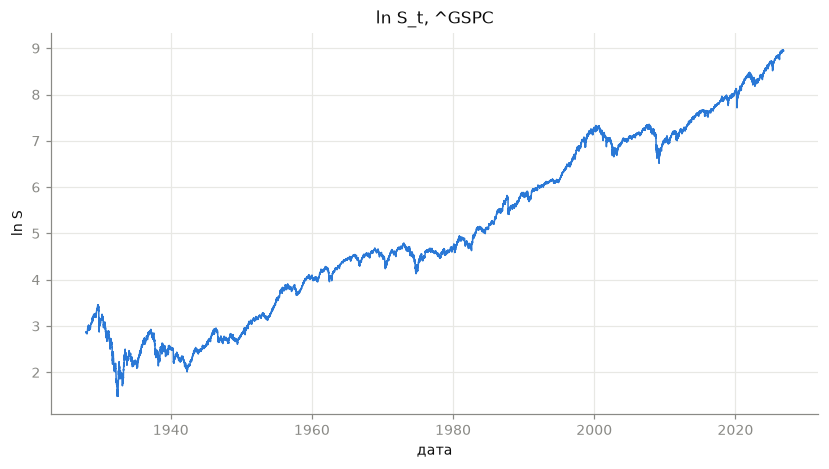

In [5]:
try:
    prices = fetch_prices(TICKER, refresh=REFRESH_DATA)
except ImportError as error:
    raise SystemExit("Установите зависимости: uv sync (нужен yfinance)") from error
logp = np.log(prices.to_numpy())
dates = prices.index
print(f"{TICKER}: {len(prices)} закрытий, {dates[0].date()} — {dates[-1].date()}")

fig, ax = plt.subplots()
ax.plot(dates, logp, color=C1, linewidth=1)
ax.set(title=f"ln S_t, {TICKER}", xlabel="дата", ylabel="ln S")
plt.show()

## Оценки по всей истории и по десятилетиям

Контрольная таблица: порядок величин параметров на длинных отрезках. Оба метода оценки
`H` показаны рядом; R/S с поправкой Анниса–Ллойда систематически сжимает `H` к 0.5
(см. синтетическую проверку в 07).

In [6]:
def estimate_row(segment, label):
    rs, dfa = estimate(segment, D, "rs"), estimate(segment, D, "dfa")
    return {"период": label, "дней": len(segment) - 1, "a (в месяц)": rs.a,
            "σ (в месяц)": rs.sigma, "H (R/S)": rs.H_raw, "H (DFA)": dfa.H_raw,
            "μ = a/σ": rs.mu, "σ при H=DFA": dfa.sigma, "μ при H=DFA": dfa.mu}

rows = [estimate_row(logp, "вся история")]
years = dates.year
for decade in range(years.min() // 10 * 10, years.max() + 1, 10):
    mask = (years >= decade) & (years < decade + 10)
    if mask.sum() > 300:
        rows.append(estimate_row(logp[mask], f"{decade}-е"))
long_run = pd.DataFrame(rows)
display(long_run.style.format(precision=4))
long_run.to_csv(OUT / "long_run_estimates.csv", index=False)

,период,дней,a (в месяц),σ (в месяц),H (R/S),H (DFA),μ = a/σ,σ при H=DFA,μ при H=DFA
0,вся история,24820,0.0051,0.0562,0.5090,0.5103,0.0914,0.0564,0.0910
1,1920-е,499,0.0082,0.0806,0.4915,0.3773,0.1015,0.0569,0.1437
2,1930-е,2495,-0.0045,0.1056,0.5147,0.5389,-0.0423,0.1137,-0.0393
3,1940-е,2499,0.0024,0.0473,0.5160,0.5372,0.0506,0.0505,0.0474
4,1950-е,2510,0.0107,0.0333,0.5010,0.5181,0.3219,0.0350,0.3056
5,1960-е,2488,0.0036,0.0331,0.5385,0.5462,0.1096,0.0339,0.1070
6,1970-е,2525,0.0012,0.0446,0.5419,0.5406,0.0278,0.0444,0.0279
7,1980-е,2527,0.0100,0.0510,0.5047,0.5040,0.1964,0.0509,0.1968
8,1990-е,2527,0.0117,0.0366,0.4649,0.4181,0.3197,0.0317,0.3686
9,2000-е,2514,-0.0022,0.0591,0.4728,0.4457,-0.0376,0.0544,-0.0409


## Скользящие оценки

Для каждого месяца параметры оцениваются по `W` приростам, заканчивающимся в точке
решения `t₀`. Будущее блока не используется.

Месяцев: 1133 первое решение: 1932-01-11


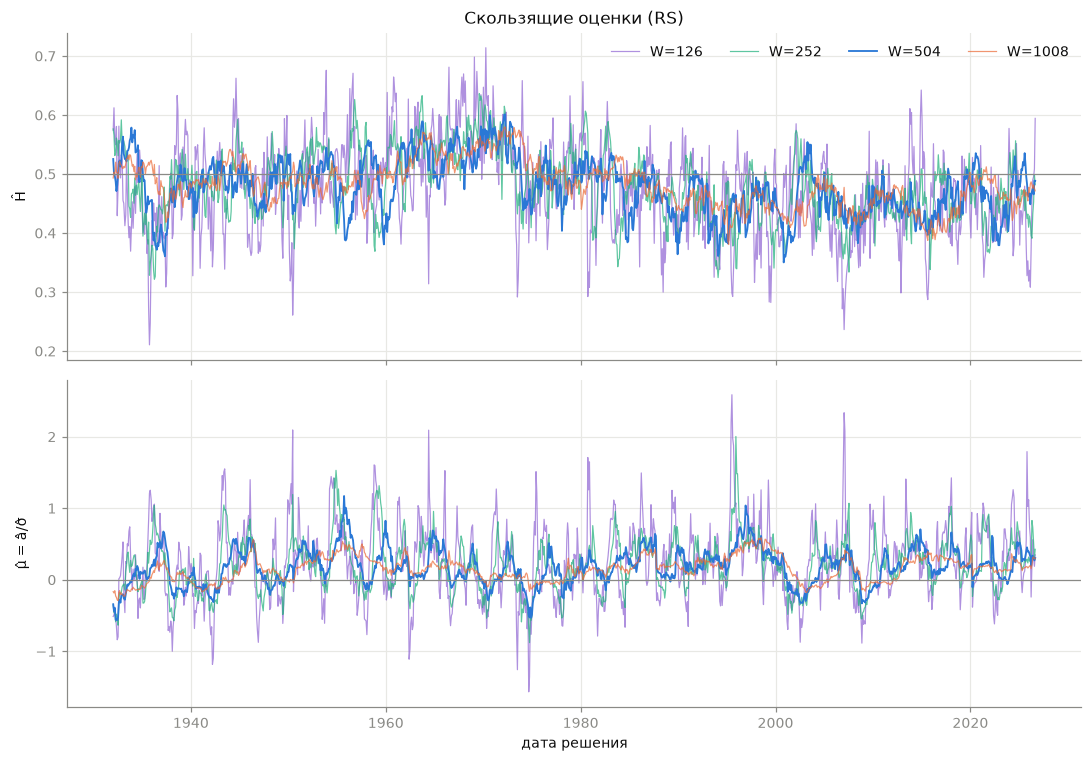

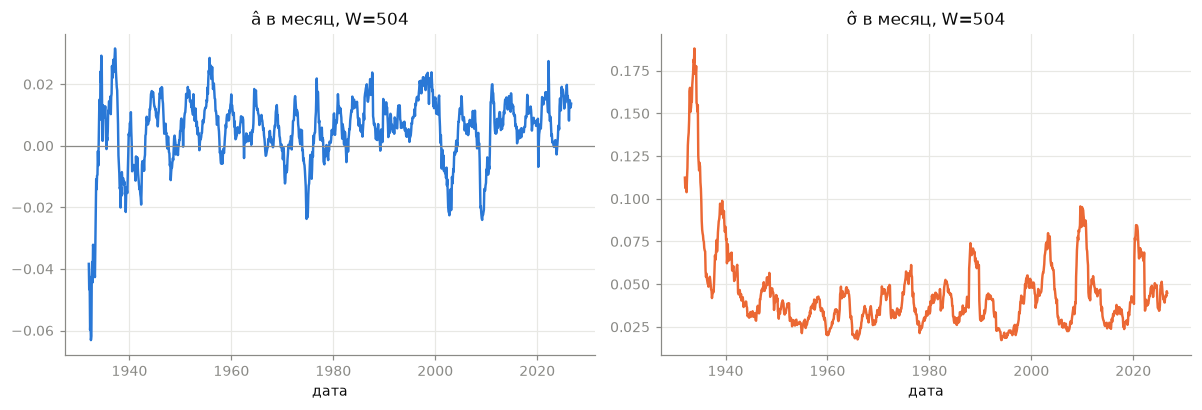

,count,mean,std,min,25%,50%,75%,max
a,1133.0000,0.0053,0.0112,-0.0631,0.0009,0.0066,0.0121,0.0316
sigma,1133.0000,0.0452,0.0247,0.0173,0.0307,0.0391,0.0495,0.1880
H,1133.0000,0.4768,0.0474,0.3503,0.4424,0.4771,0.5101,0.6011
mu,1133.0000,0.1815,0.2510,-0.5640,0.0210,0.1754,0.3384,1.1712


In [7]:
blocks = month_blocks(len(logp), D, warmup=max(WINDOWS))
frame = block_frame(dates, blocks)
rolling = {}
for w in WINDOWS:
    est = rolling_estimates(logp, blocks[:, 0], w, D, HURST_METHOD)
    rolling[w] = pd.concat([frame, est.drop(columns="decision_idx")], axis=1)
    rolling[w].to_csv(OUT / f"rolling_W{w}_{HURST_METHOD}.csv", index=False)
print("Месяцев:", len(frame), "первое решение:", frame.decision_date.iloc[0].date())

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for w, color in zip(WINDOWS, (C4, C3, C1, C2)):
    axes[0].plot(rolling[w].decision_date, rolling[w].H, color=color, label=f"W={w}",
                 linewidth=1.2 if w == WINDOW else 0.8, alpha=1 if w == WINDOW else 0.7)
    axes[1].plot(rolling[w].decision_date, rolling[w].mu, color=color, label=f"W={w}",
                 linewidth=1.2 if w == WINDOW else 0.8, alpha=1 if w == WINDOW else 0.7)
axes[0].axhline(0.5, color=MUTED, linewidth=0.8)
axes[0].set(ylabel="Ĥ", title=f"Скользящие оценки ({HURST_METHOD.upper()})")
axes[1].axhline(0, color=MUTED, linewidth=0.8)
axes[1].set(ylabel="μ̂ = â/σ̂", xlabel="дата решения")
axes[0].legend(ncol=len(WINDOWS))
fig.tight_layout(); fig.savefig(OUT / "rolling_H_mu.png", dpi=160, bbox_inches="tight")
plt.show()

base = rolling[WINDOW]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(base.decision_date, base.a, color=C1); axes[0].axhline(0, color=MUTED, linewidth=0.8)
axes[0].set(title=f"â в месяц, W={WINDOW}", xlabel="дата")
axes[1].plot(base.decision_date, base.sigma, color=C2)
axes[1].set(title=f"σ̂ в месяц, W={WINDOW}", xlabel="дата")
fig.tight_layout(); fig.savefig(OUT / f"rolling_a_sigma_W{WINDOW}.png", dpi=160, bbox_inches="tight")
plt.show()
display(base[["a", "sigma", "H", "mu"]].describe().T.style.format(precision=4))

## Доверительные интервалы параметров

Параметрический бутстреп: по оценённым `(â, σ̂, Ĥ)` симулируются `N_BOOT` окон той
же длины, параметры переоцениваются, берутся перцентили. Интервал описывает
статистическую неопределённость оценки при верной модели; смещение метода он не
устраняет.

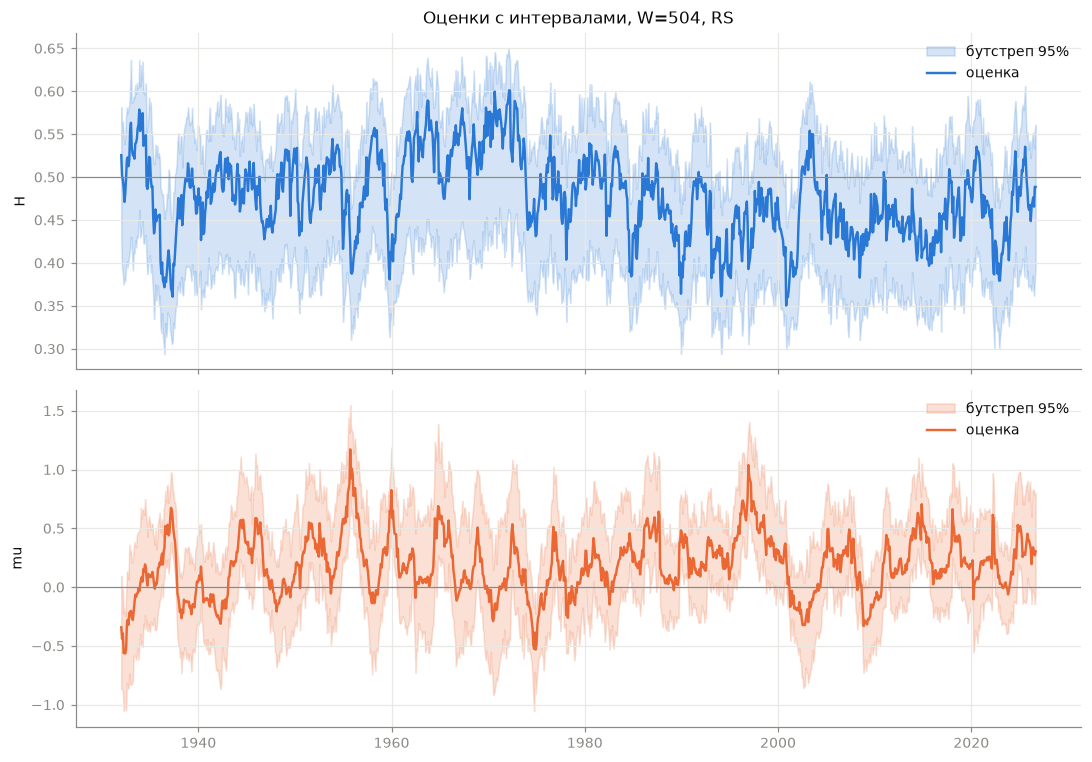

Последняя дата 2026-08-27: H=0.489 [0.397, 0.561], μ=0.304 [-0.054, 0.800]


In [8]:
selected = base.iloc[::BOOT_EVERY]
ci_rows = []
for _, row in selected.iterrows():
    est = estimate(logp[int(row.decision_idx) - WINDOW: int(row.decision_idx) + 1], D, HURST_METHOD)
    boot = bootstrap_estimates(est, WINDOW, n_boot=N_BOOT, seed=int(row.decision_idx))
    record = {"decision_date": row.decision_date, "H": est.H, "mu": est.mu, "sigma": est.sigma, "a": est.a}
    for name in ("H", "mu", "sigma", "a"):
        record[f"{name}_low"], record[f"{name}_high"] = percentile_ci(boot[name], CONFIDENCE)
    ci_rows.append(record)
ci = pd.DataFrame(ci_rows)
ci.to_csv(OUT / f"bootstrap_ci_W{WINDOW}_{HURST_METHOD}.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, name, color, ref in ((axes[0], "H", C1, 0.5), (axes[1], "mu", C2, 0.0)):
    ax.fill_between(ci.decision_date, ci[f"{name}_low"], ci[f"{name}_high"], color=color, alpha=0.2,
                    label=f"бутстреп {100*CONFIDENCE:g}%")
    ax.plot(ci.decision_date, ci[name], color=color, label="оценка")
    ax.axhline(ref, color=MUTED, linewidth=0.8)
    ax.set(ylabel=name)
    ax.legend()
axes[0].set(title=f"Оценки с интервалами, W={WINDOW}, {HURST_METHOD.upper()}")
fig.tight_layout(); fig.savefig(OUT / f"bootstrap_ci_W{WINDOW}.png", dpi=160, bbox_inches="tight")
plt.show()
last = ci.iloc[-1]
print(f"Последняя дата {last.decision_date.date()}: "
      f"H={last.H:.3f} [{last.H_low:.3f}, {last.H_high:.3f}], "
      f"μ={last.mu:.3f} [{last.mu_low:.3f}, {last.mu_high:.3f}]")

## Оценки на фоне практических границ

Ключевая картинка: где S&P 500 находится в плоскости `(H, μ)` относительно зон
«не покупать» (`μ ≤ μ₁(H)`), «держать до конца» (`μ ≥ μ₂(H)`) и средней зоны, где
нужна стратегия остановки.

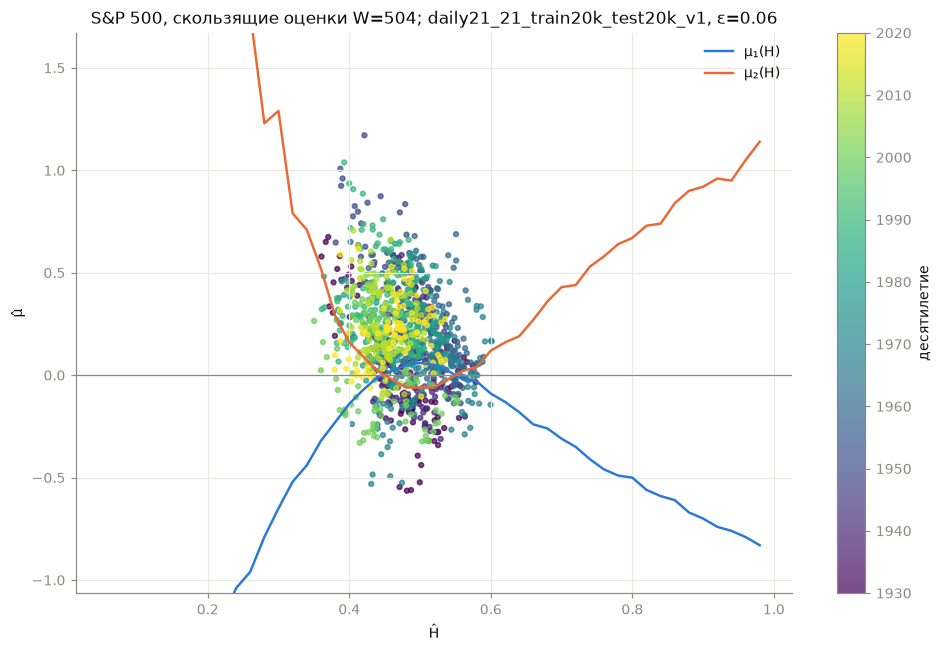

Доля месяцев по режимам:


,cash,policy,hold
W,,,
126,29.8%,10.9%,59.2%
252,29.0%,5.6%,65.3%
504,24.2%,5.4%,70.4%
1008,24.4%,1.2%,74.4%


Последнее окно: режим hold; бутстреп-вероятности режимов:


,P
cash,12.5%
policy,3.5%
hold,84.0%


Результаты: /Users/armkilikia/optimal-stopping-fbm/result_optimal_stopping/empirical/daily21_21_train20k_test20k_v1/estimation_eps0.06


In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
f = boundaries.frame()
ax.plot(f.H, f.mu1, color=C1, label="μ₁(H)")
ax.plot(f.H, f.mu2, color=C2, label="μ₂(H)")
decade = (base.decision_date.dt.year // 10 * 10)
scatter = ax.scatter(base.H, base.mu, c=decade, cmap="viridis", s=10, alpha=0.7)
fig.colorbar(scatter, ax=ax, label="десятилетие")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set(xlabel="Ĥ", ylabel="μ̂", title=f"S&P 500, скользящие оценки W={WINDOW}; {RUN_ID}, ε={EPSILON:g}",
       ylim=(np.nanmin(base.mu) - 0.5, np.nanmax(base.mu) + 0.5))
ax.legend()
fig.tight_layout(); fig.savefig(OUT / f"plane_H_mu_W{WINDOW}.png", dpi=160, bbox_inches="tight")
plt.show()

shares = {}
for w in WINDOWS:
    reg = pd.Series([boundaries.regime(h, m) for h, m in zip(rolling[w].H, rolling[w].mu)])
    shares[w] = reg.value_counts(normalize=True).reindex([CASH, POLICY, HOLD], fill_value=0)
shares = pd.DataFrame(shares).T.rename_axis("W")
print("Доля месяцев по режимам:")
display(shares.style.format("{:.1%}"))
shares.to_csv(OUT / "regime_shares.csv")

est = estimate(logp[-WINDOW - 1:], D, HURST_METHOD)
boot = bootstrap_estimates(est, WINDOW, n_boot=N_BOOT, seed=1)
probs = pd.Series([boundaries.regime(h, m) for h, m in zip(boot.H, boot.mu)]).value_counts(normalize=True)
print(f"Последнее окно: режим {boundaries.regime(est.H, est.mu)}; бутстреп-вероятности режимов:")
display(probs.reindex([CASH, POLICY, HOLD], fill_value=0).to_frame("P").style.format("{:.1%}"))
print("Результаты:", OUT)